# 5. What sets the wander? A small spot model

Two completely different things make a spot-derived period move from sector to sector:

* **Shear** — the star's surface turns faster at the equator than near the poles, so spots at different latitudes have different periods, and different sectors catch different spots.
* **Spot evolution** — spots grow and fade *within* the 27-day window, so the wave changes shape while we time it and the fitted period is nudged.

The brightness curves cannot tell these apart. So we build fake stars where **we choose the cause**, run them through the identical measurement, and see which cause produces the numbers we observe.

**The model.** Butterpy (Claytor et al. 2022) grows and fades spots on a rotating star. Each fake star gets a real star's period, its real TESS timestamps, its real brightness amplitude and its real leftover noise. Spot lifetimes come from the Kepler relation of Giles et al. (2017). Two knobs: shear **off** (rigid) or **on** (the Collier Cameron 2007 value for that temperature); spot lifetime at **1×, 2× or 3×** the Giles relation.

This is a small grid — 20 Sun-like and 20 M-dwarf twins, 6 settings each — where the full pipeline ran 3,888 simulations. The conclusions are the same; the exact numbers are not, and the notebook says which is which.

In [1]:
import sys; sys.path.insert(0, "..")
import json, time, os
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import helpers as h
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

In [2]:
import spotmodel as m
from concurrent.futures import ProcessPoolExecutor

stars = pd.read_csv("../results/stars_original.csv")
lists = {r["tic_id"]: r for r in h.read_star_list("original_450")}
cache = h.DATA / "lightcurves" / "original"
def pick(lo, hi, n=20):
    sel = stars[(stars.teff >= lo) & (stars.teff < hi) & np.isfinite(stars.ratio_white)].sort_values("tic_id").head(n)
    return [lists[int(t)] for t in sel.tic_id]
twins = {"M dwarfs 3000-3800 K": pick(3000, 3800), "Sun-like 5000-6000 K": pick(5000, 6000)}
configs = [(shear, life) for shear in (False, True) for life in (1.0, 2.0, 3.0)]
print({k: len(v) for k, v in twins.items()}, "twins;", len(configs), "settings each ->", sum(len(v) for v in twins.values()) * len(configs), "simulations")

{'M dwarfs 3000-3800 K': 20, 'Sun-like 5000-6000 K': 20} twins; 6 settings each -> 240 simulations


In [3]:
out_csv = Path("../results/spot_model.csv")
if out_csv.exists():
    model = pd.read_csv(out_csv); print("loaded cached", out_csv.name)
else:
    jobs = [(row, cache, shear, life) for band in twins.values() for row in band for shear, life in configs]
    t0 = time.time()
    with ProcessPoolExecutor(max_workers=max(1, (os.cpu_count() or 2) - 2)) as pool:
        results = [r for r in pool.map(m.run_config, jobs, chunksize=2) if r is not None]
    model = pd.DataFrame(results); model.to_csv(out_csv, index=False)
    print(f"{len(model)} simulations in {(time.time()-t0)/60:.1f} min")
model["band"] = np.where(model.teff < 3800, "M dwarfs 3000-3800 K", "Sun-like 5000-6000 K")
model.head()

loaded cached spot_model.csv


,tic_id,teff,period,shear_on,lifetime_factor,lifetime_days,sectors,simulated_wander,simulated_floor,simulated_excess,simulated_ratio,band
0,3544322,3018.0,4.1559,False,1.0,165.767879,9,0.034935,0.003011,0.034805,11.604160,M dwarfs 3000-3800 K
1,3544322,3018.0,4.1559,False,2.0,331.535758,9,0.007962,0.002775,0.007463,2.868794,M dwarfs 3000-3800 K
2,3544322,3018.0,4.1559,False,3.0,497.303637,9,0.002465,0.001726,0.001761,1.428703,M dwarfs 3000-3800 K
3,3544322,3018.0,4.1559,True,1.0,165.767879,9,0.027266,0.002412,0.027159,11.304367,M dwarfs 3000-3800 K
4,3544322,3018.0,4.1559,True,2.0,331.535758,9,0.009293,0.001671,0.009141,5.560950,M dwarfs 3000-3800 K


In [4]:
# Observed excess (white floor, as in the model) for the SAME twin stars, for a like-for-like comparison.
obs = {band: stars[stars.tic_id.isin([r["tic_id"] for r in rows_])].excess_white.median() for band, rows_ in twins.items()}
table = model.groupby(["band", "shear_on", "lifetime_factor"]).simulated_excess.median().unstack("lifetime_factor")
table.insert(0, "observed", [obs[b] for b, _ in table.index])
print("median excess wander in quadrature (rad/day): observed twins vs model, by shear and spot-lifetime factor")
table.round(4)

median excess wander in quadrature (rad/day): observed twins vs model, by shear and spot-lifetime factor


lifetime_factor                observed     1.0     2.0     3.0
band                 shear_on                                  
M dwarfs 3000-3800 K False       0.0072  0.0265  0.0164  0.0130
                     True        0.0072  0.0247  0.0227  0.0168
Sun-like 5000-6000 K False       0.0288  0.0273  0.0260  0.0164
                     True        0.0288  0.0362  0.0248  0.0189

M dwarfs 3000-3800 K: model/observed at 1x Giles = 3.69 (shear off), 3.44 (shear on); shear changes the model by 7%
Sun-like 5000-6000 K: model/observed at 1x Giles = 0.95 (shear off), 1.26 (shear on); shear changes the model by 33%


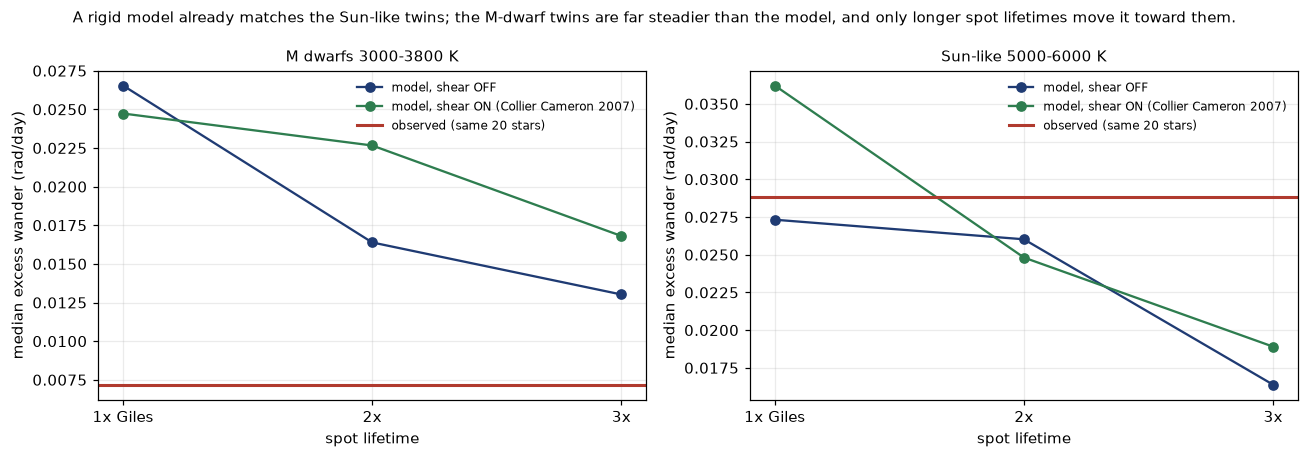

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for ax, band in zip(axes, twins):
    sub = table.loc[band]
    for shear_on, col, lab in [(False, "#1f3b73", "model, shear OFF"), (True, "#2e7d4f", "model, shear ON (Collier Cameron 2007)")]:
        ax.plot([1, 2, 3], sub.loc[shear_on, [1.0, 2.0, 3.0]].to_numpy(), "o-", color=col, label=lab)
    ax.axhline(obs[band], color="#b03a2e", lw=2, label="observed (same 20 stars)")
    ax.set_xticks([1, 2, 3]); ax.set_xticklabels(["1x Giles", "2x", "3x"]); ax.set_xlabel("spot lifetime")
    ax.set_ylabel("median excess wander (rad/day)"); ax.set_title(band, fontsize=10); ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.25)
fig.suptitle("A rigid model already matches the Sun-like twins; the M-dwarf twins are far steadier than the model, and only longer spot lifetimes move it toward them.", fontsize=10)
fig.tight_layout(); fig.savefig("../figures/05_model.png", dpi=150)
for band in twins:
    off1 = table.loc[(band, False), 1.0]; on1 = table.loc[(band, True), 1.0]
    print(f"{band}: model/observed at 1x Giles = {off1/obs[band]:.2f} (shear off), {on1/obs[band]:.2f} (shear on); shear changes the model by {100*abs(on1-off1)/off1:.0f}%")

**Reading it (numbers from the table above; 20 twins per band, so expect ±30% scatter on any one entry).**

* *Sun-like twins:* with shear **off** the model lands on the observed wander (ratio ≈ 0.95). Switching the Sun-like shear **on** moves it by about a third — and in the *wrong* direction for a shear story to be needed: the rigid model already matches. At realistic shear the wander is set by how the spots evolve, not by shear. (Full pipeline, 150 twins: <25% change; a shear sweep shows the wander responds to shear only above ΔΩ ≈ 0.2–0.3 rad/day, 3–6× the imaged Sun-like values.)
* *M-dwarf twins:* at the Giles lifetimes the model wanders **3–4× more** than the real stars, shear on or off. Lengthening the spot lifetime brings it down — halved at 3× — but in this small grid, which turns only the lifetime knob, it is still about 1.8× above the observed value. (Full pipeline: over-prediction 2.4×; a 3,888-run grid that also varied spot number, latitude and emergence rate matched the M dwarfs at ≈3× the Giles relation, and lifetime was the only knob that moved the answer.)

**Conclusion licensed by the model:** the quantity we measure is governed by how long spot patterns persist, and the M dwarfs' patterns persist longer than the Kepler relation predicts. **Not licensed:** that they shear less — the model shows this measurement cannot see shear at realistic levels. The exact lifetime factor is the full grid's job, not this notebook's.